In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Set visualization style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_csv("CaseStudy_Jan_Samadhan_Grievances.csv")

# Display the original date values
print("Original startdate values:")
print(df["startdate"].head(10).tolist())

print("\nOriginal enddate values:")
print(df["enddate"].head(10).tolist())

# Check the data types
print("\nOriginal data types:")
print(df[["startdate", "enddate"]].dtypes)


Original startdate values:
['2025-05-23', '2025-02-02', '2025-01-28', '2026-08-27', '2025-12-15', '2026-01-25', '2025-02-14', '2025-10-28', '2025-03-13', '2025-08-27']

Original enddate values:
[nan, '2025-02-07', '2025-04-11', nan, '2026-01-21', nan, '2025-04-15', nan, nan, nan]

Original data types:
startdate    str
enddate      str
dtype: object


In [4]:
# Task 1.1 Load the dataset and identify data types
# Load the grievance dataset

# Load the dataset
df = pd.read_csv("CaseStudy_Jan_Samadhan_Grievances.csv")

# Convert dates using DD-MM-YYYY format
df["startdate"] = pd.to_datetime(
    df["startdate"], format="%d-%m-%Y", errors="coerce"
)

df["enddate"] = pd.to_datetime(
    df["enddate"], format="%d-%m-%Y", errors="coerce"
)

# Display dataset details
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five records
display(df.head())

Dataset loaded successfully!
Dataset shape: (900, 9)


,Department,Status,CitizenComplaintNarrative,ComplaintID,State,category,startdate,enddate,ResolutionDays
0,Electricity Department,In Progress,There are frequent power interruptions in our ...,JSM100001,Telangana,Poor Service Quality,NaT,NaT,NaN
1,Electricity Department,Resolved,The electricity bill contains incorrect charges.,JSM100002,Tamil Nadu,Poor Service Quality,NaT,NaT,5.0
2,Electricity Department,Resolved,My electricity connection application has not ...,JSM100003,Andhra Pradesh,Poor Service Quality,NaT,NaT,73.0
3,Public Works Department,In Progress,Construction work on the public road has remai...,JSM100004,Delhi,Infrastructure Issues,NaT,NaT,NaN
4,Health Department,Resolved,I visited the government hospital several time...,JSM100005,Karnataka,Poor Service Quality,NaT,NaT,37.0


In [5]:
# Inspect the dataset - structure and data types
df.info()

# Statistical summary
display(df.describe(include="all"))

# Check the number of unique values in each column
print("\nUnique values in each column:")
print(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype        
---  ------                     --------------  -----        
 0   Department                 900 non-null    str          
 1   Status                     900 non-null    str          
 2   CitizenComplaintNarrative  900 non-null    str          
 3   ComplaintID                900 non-null    str          
 4   State                      900 non-null    str          
 5   category                   900 non-null    str          
 6   startdate                  0 non-null      datetime64[s]
 7   enddate                    0 non-null      datetime64[s]
 8   ResolutionDays             451 non-null    float64      
dtypes: datetime64[s](2), float64(1), str(6)
memory usage: 183.8 KB


,Department,Status,CitizenComplaintNarrative,ComplaintID,State,category,startdate,enddate,ResolutionDays
count,900,900,900,900,900,900,0,0,451.000000
unique,10,5,50,900,10,6,NaN,NaN,NaN
top,Police Department,Resolved,I have reported a public safety issue but have...,JSM100001,Karnataka,Poor Service Quality,NaN,NaN,NaN
freq,101,319,28,1,99,194,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,42.625277
min,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,20.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,42.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,64.000000
max,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,90.000000



Unique values in each column:
Department                    10
Status                         5
CitizenComplaintNarrative     50
ComplaintID                  900
State                         10
category                       6
startdate                      0
enddate                        0
ResolutionDays                91
dtype: int64


In [6]:
#Identify structured and unstructured data
# Structured Data Fields - Department, Status, ComplaintID, State, category, startdate, enddate, ResolutionDays
# UnStructured Data Fields - CitizenComplaintNarrative
# Field - ResolutionDays may have Null values

In [7]:
# Task 1.2 Handle missing values and clean text
# Check missing values
# Count missing values in each column
print("Missing values before cleaning:")
print(df.isnull().sum())

# Calculate missing-value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentage:")
print(missing_percentage.round(2))

Missing values before cleaning:
Department                     0
Status                         0
CitizenComplaintNarrative      0
ComplaintID                    0
State                          0
category                       0
startdate                    900
enddate                      900
ResolutionDays               449
dtype: int64

Missing value percentage:
Department                     0.00
Status                         0.00
CitizenComplaintNarrative      0.00
ComplaintID                    0.00
State                          0.00
category                       0.00
startdate                    100.00
enddate                      100.00
ResolutionDays                49.89
dtype: float64


In [8]:
# Handle missing values
# Remove duplicate complaint records
df = df.drop_duplicates(subset=["ComplaintID"])

# Fill missing categorical values
df["Department"] = df["Department"].fillna("Unknown")
df["Status"] = df["Status"].fillna("Unknown")
df["State"] = df["State"].fillna("Unknown")
df["category"] = df["category"].fillna("Unclassified")

# Fill missing complaint narratives
df["CitizenComplaintNarrative"] = (
    df["CitizenComplaintNarrative"].fillna("")
)

# Keep missing end dates as NaT because they may represent unresolved complaints

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Department                     0
Status                         0
CitizenComplaintNarrative      0
ComplaintID                    0
State                          0
category                       0
startdate                    900
enddate                      900
ResolutionDays               449
dtype: int64


In [9]:
import re

In [10]:
#Clean complaint text
def clean_text(text):

    # Convert text to lowercase
    text = str(text).lower()

    # Remove special characters and retain letters, numbers and spaces
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply cleaning to complaint narratives
df["CitizenComplaintNarrative"] = (
    df["CitizenComplaintNarrative"].apply(clean_text)
)

# Display original dataset fields after cleaning
display(df[[
    "ComplaintID",
    "Department",
    "CitizenComplaintNarrative"
]].head(10))

,ComplaintID,Department,CitizenComplaintNarrative
0,JSM100001,Electricity Department,there are frequent power interruptions in our ...
1,JSM100002,Electricity Department,the electricity bill contains incorrect charges
2,JSM100003,Electricity Department,my electricity connection application has not ...
3,JSM100004,Public Works Department,construction work on the public road has remai...
4,JSM100005,Health Department,i visited the government hospital several time...
5,JSM100006,Water Resources Department,the drainage system is blocked and wastewater ...
6,JSM100007,Electricity Department,the electricity meter installed at my residenc...
7,JSM100008,Transport Department,public transport buses are not operating regul...
8,JSM100009,Police Department,my police complaint has not been registered de...
9,JSM100010,Pension Department,the pension application has not been approved ...


In [11]:
# Calculate resolution time in days
df["ResolutionDays"] = (
    df["enddate"] - df["startdate"]
).dt.days

# Display resolution statistics
print("Resolution time statistics:")
display(df["ResolutionDays"].describe())

# Count complaints with available resolution times
print("Complaints with resolution time:",
      df["ResolutionDays"].notna().sum())

Resolution time statistics:


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ResolutionDays, dtype: float64

Complaints with resolution time: 0


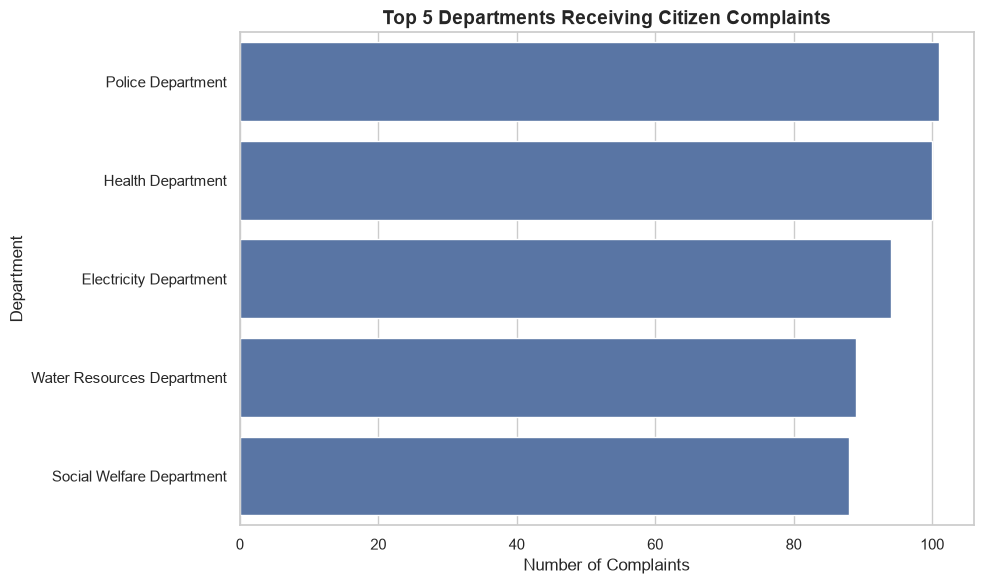

In [12]:
# Task 1.3 Generate visual insights
# Count complaints by department
department_counts = (
    df["Department"]
    .value_counts()
    .head(5)
    .reset_index()
)

department_counts.columns = ["Department", "Complaint Count"]

# Plot the results
plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_counts,
    x="Complaint Count",
    y="Department"
)

plt.title("Top 5 Departments Receiving Citizen Complaints",
          fontsize=14, fontweight="bold")

plt.xlabel("Number of Complaints")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

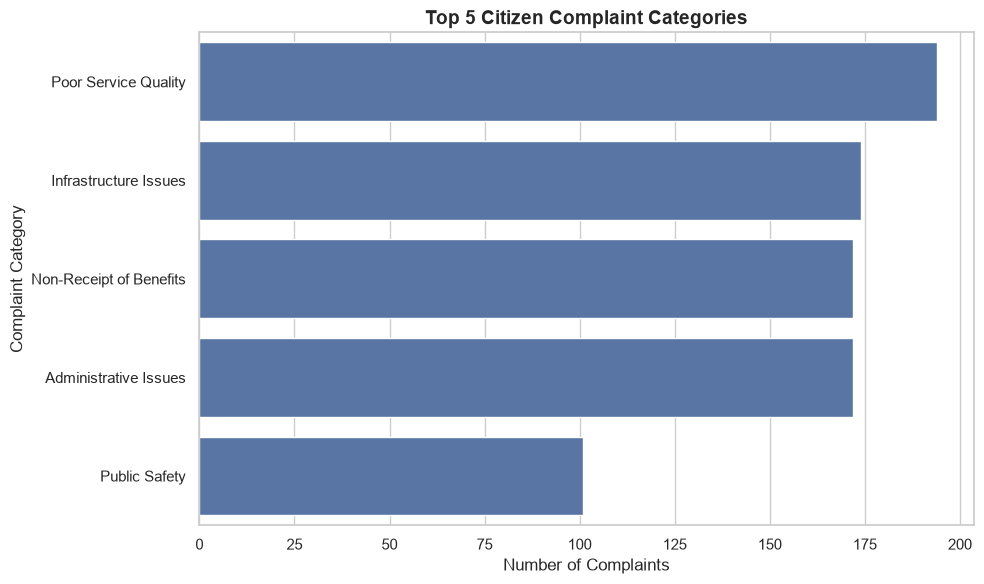

In [13]:
# Count complaints by category
category_counts = (
    df["category"]
    .value_counts()
    .head(5)
    .reset_index()
)

category_counts.columns = ["Category", "Complaint Count"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_counts,
    x="Complaint Count",
    y="Category"
)

plt.title("Top 5 Citizen Complaint Categories",
          fontsize=14, fontweight="bold")

plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Category")

plt.tight_layout()
plt.show()

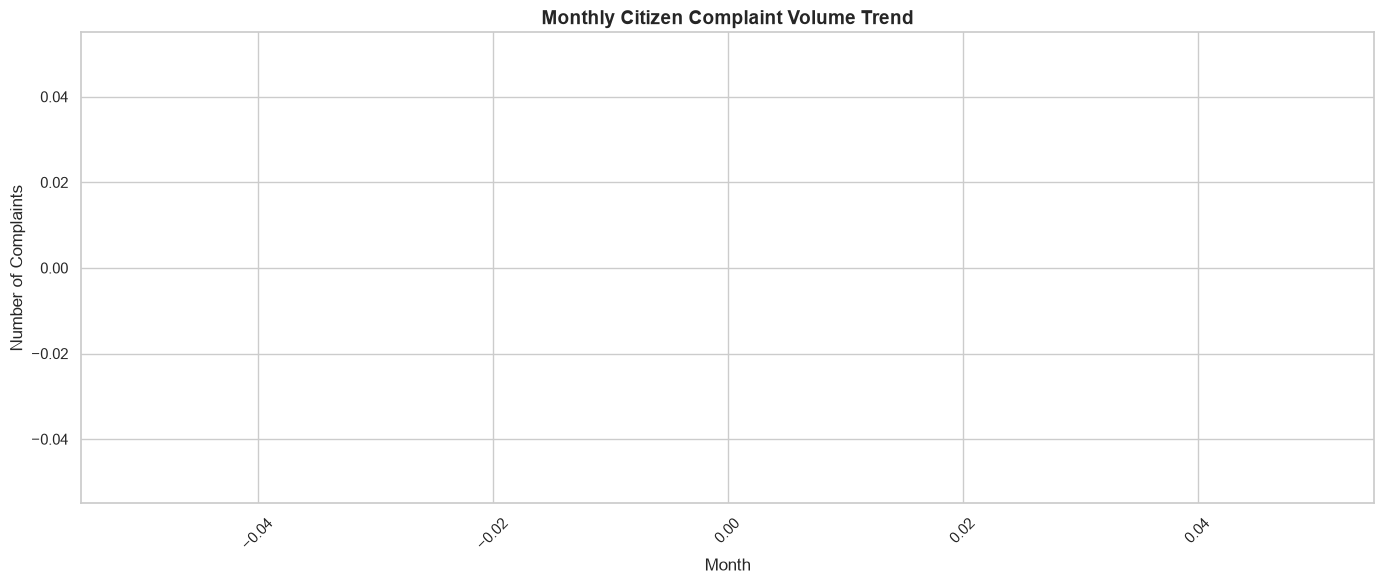

In [14]:
# Extract month and year from complaint start date
df["ComplaintMonth"] = df["startdate"].dt.to_period("M")

# Calculate monthly complaint volume
monthly_complaints = (
    df.groupby("ComplaintMonth")
    .size()
    .reset_index(name="Complaint Count")
)

# Convert Period to string for plotting
monthly_complaints["ComplaintMonth"] = (
    monthly_complaints["ComplaintMonth"].astype(str)
)

# Plot monthly complaint volume
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_complaints,
    x="ComplaintMonth",
    y="Complaint Count",
    marker="o"
)

plt.title("Monthly Citizen Complaint Volume Trend",
          fontsize=14, fontweight="bold")

plt.xlabel("Month")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

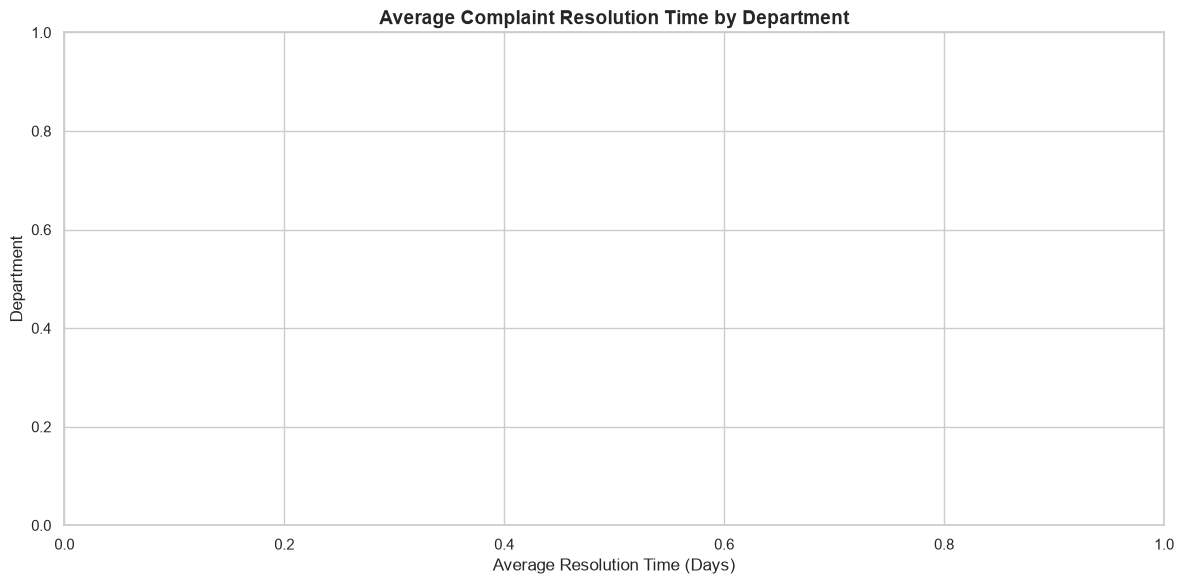

In [15]:
# Calculate average resolution time by department
avg_resolution = (
    df.dropna(subset=["ResolutionDays"])
    .groupby("Department")["ResolutionDays"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=avg_resolution,
    x="ResolutionDays",
    y="Department"
)

plt.title("Average Complaint Resolution Time by Department",
          fontsize=14, fontweight="bold")

plt.xlabel("Average Resolution Time (Days)")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

In [16]:
# Save the cleaned DataFrame
df.to_csv("CaseStudy_Jan_Samadhan_Grievances_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
